# Assignment Problems: Day 6
The problems require access to the file named ‘Dataset_Day6.csv’, provided with this assignment. (Use Random State = 50)

In [1]:
import numpy as np
import pandas as pd
from math import log
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.linear_model import Ridge
from sklearn.linear_model import Lasso
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

* Treat the data to replace all missing data with median/ mode (whichever applicable), and remove all rows with outliers in column: ‘Price’
* Use One Hot Encoding to encode all character variables.

1.7474185861795075
<class 'pandas.core.frame.DataFrame'>
Int64Index: 1237 entries, 0 to 1258
Data columns (total 14 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Area            1237 non-null   float64
 1   BHK             1237 non-null   int64  
 2   Bathroom        1237 non-null   int32  
 3   Parking         1237 non-null   int32  
 4   Price           1237 non-null   float64
 5   Furnished       1237 non-null   uint8  
 6   Semi-Furnished  1237 non-null   uint8  
 7   Unfurnished     1237 non-null   uint8  
 8   Almost_ready    1237 non-null   uint8  
 9   Ready_to_move   1237 non-null   uint8  
 10  New_Property    1237 non-null   uint8  
 11  Resale          1237 non-null   uint8  
 12  Apartment       1237 non-null   uint8  
 13  Builder_Floor   1237 non-null   uint8  
dtypes: float64(2), int32(2), int64(1), uint8(9)
memory usage: 59.2 KB


(None,
 <Axes: >,
        Area  BHK  Bathroom  Parking     Price  Furnished  Semi-Furnished  \
 0 -0.425019    3         2        1 -0.578361          0               1   
 1 -0.456905    2         2        1 -0.636952          0               1   
 2 -0.329359    2         2        1 -0.226814          1               0   
 3 -0.552565    2         2        1 -0.668200          0               1   
 4 -0.520679    2         2        1 -0.590079          0               1   
 
    Unfurnished  Almost_ready  Ready_to_move  New_Property  Resale  Apartment  \
 0            0             0              1             1       0          0   
 1            0             0              1             1       0          1   
 2            0             0              1             0       1          1   
 3            0             0              1             0       1          0   
 4            0             0              1             1       0          0   
 
    Builder_Floor  
 0        

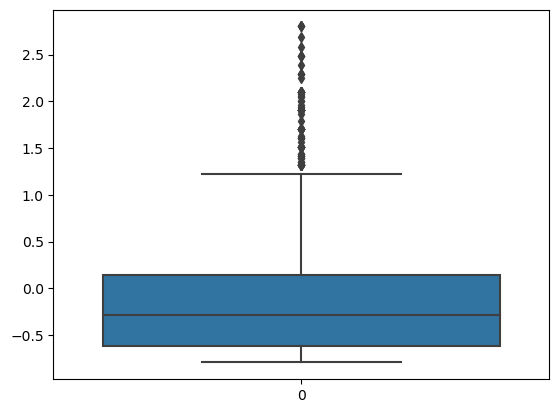

In [2]:
data = pd.read_csv("Dataset_Day6.csv")

# As we can see that columns (Bathroom,Furnishing,Parking,Type) have null values so we will treat them according to their data type
# * Bathroom - Discrete (replace with median)
# * Furnishing - categorical (replace with mode)
# * Parking - Discrete (replace with median)
# * Type - categorical (replace with mode)

# replacing Null values
data["Bathroom"].fillna(data["Bathroom"].median(),inplace=True)
data["Parking"].fillna(data["Parking"].median(),inplace=True)
data["Furnishing"].fillna(data["Furnishing"].value_counts().reset_index().loc[0][0],inplace=True)
data["Type"].fillna(data["Type"].value_counts().reset_index().loc[0][0],inplace=True)

# assigning proper datatype to attributes
data['Bathroom'] = data['Bathroom'].astype(int)
data["Parking"] = data["Parking"].astype(int)

# Standard scaling of the continuous columns only
for i in ["Area","Price"]:
    data[i] = (data[i] - data[i].mean())/data[i].std()

# uotlier detection
temp = data[["Price"]]
# here in iqr method we will get around 120 outlirs from 1500 rows hence we will use it
# z-score method
outliers = data[(data["Price"] > 3)|(data["Price"] < -3)]
# here we get 1.74% of data as outliers but still have a lot of outlier data hence we won't use it
print(len(outliers)*100/len(data))
# removal of rows with outliers
OutlierFreeData = data.drop(outliers.index,axis=0)

# one hot head encoding
for col in OutlierFreeData.columns:
    if OutlierFreeData[col].dtypes == object:
        OutlierFreeData[np.sort(OutlierFreeData[col].unique())] = pd.get_dummies(OutlierFreeData[col])
        OutlierFreeData.drop(col,axis=1,inplace=True)

OutlierFreeData.info(), sns.boxplot(OutlierFreeData.Price), OutlierFreeData.head(), OutlierFreeData.corr()

* Split the data into 80% training and 20% testing data. Then, create a multiple linear regression model with target variable as ‘Price’.
* Print the model performance metrics. R2, adjusted R2, MAE

In [3]:
df = OutlierFreeData[['Area', 'BHK', 'Bathroom', 'Parking', 'Price', 'Furnished', 'Semi-Furnished', 'Unfurnished', 'Ready_to_move', 'New_Property', 'Builder_Floor']]
# ['Furnishing', 'Status', 'Transaction', 'Type', 'Almost_ready', 'New_Property', 'Apartment']

df.corr()

,Area,BHK,Bathroom,Parking,Price,Furnished,Semi-Furnished,Unfurnished,Ready_to_move,New_Property,Builder_Floor
Area,1.000000,0.414916,0.484588,-0.014162,0.507810,-0.039654,0.079601,-0.056244,-0.140919,0.082310,0.088530
BHK,0.414916,1.000000,0.762739,-0.073721,0.603833,0.056780,0.088293,-0.141181,-0.087155,0.113218,0.110403
Bathroom,0.484588,0.762739,1.000000,-0.036530,0.770980,-0.048150,0.116012,-0.089513,-0.119056,0.171496,0.136588
Parking,-0.014162,-0.073721,-0.036530,1.000000,-0.013580,-0.030559,-0.049353,0.077993,0.017093,-0.035988,-0.075915
Price,0.507810,0.603833,0.770980,-0.013580,1.000000,-0.062013,0.099591,-0.060673,-0.164166,0.186421,0.118933
Furnished,-0.039654,0.056780,-0.048150,-0.030559,-0.062013,1.000000,-0.474241,-0.262137,0.000959,-0.133973,-0.079047
Semi-Furnished,0.079601,0.088293,0.116012,-0.049353,0.099591,-0.474241,1.000000,-0.725292,0.050892,0.151759,0.106394
Unfurnished,-0.056244,-0.141181,-0.089513,0.077993,-0.060673,-0.262137,-0.725292,1.000000,-0.056534,-0.061586,-0.054810
Ready_to_move,-0.140919,-0.087155,-0.119056,0.017093,-0.164166,0.000959,0.050892,-0.056534,1.000000,-0.250293,0.030426
New_Property,0.082310,0.113218,0.171496,-0.035988,0.186421,-0.133973,0.151759,-0.061586,-0.250293,1.000000,0.227511


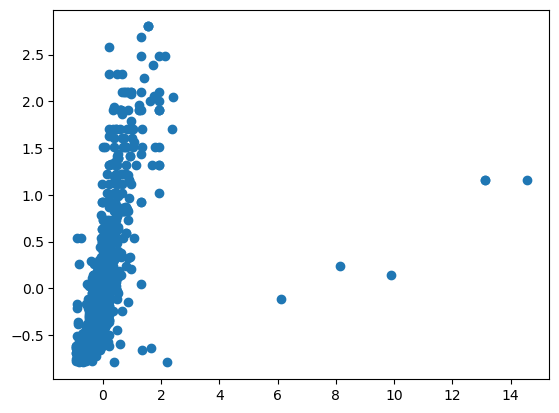

In [4]:
plt.scatter(df.Area,df.Price)

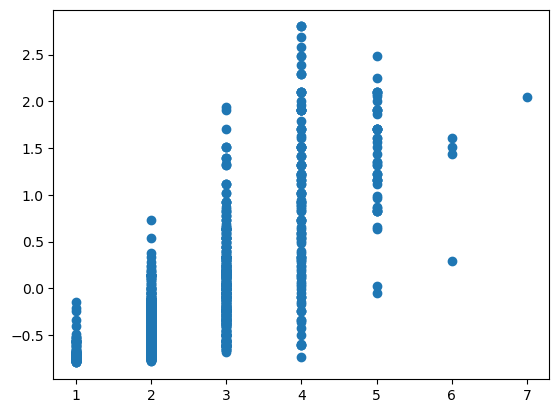

In [5]:
plt.scatter(df.Bathroom,df.Price)

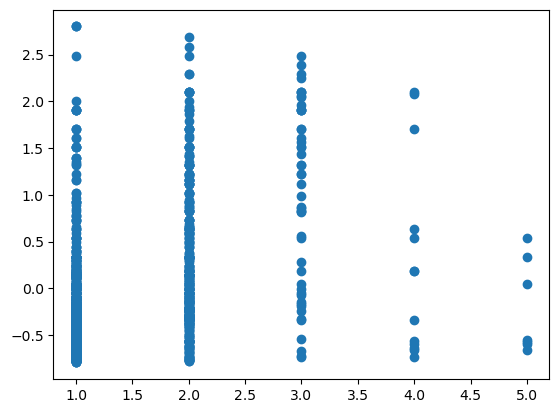

In [6]:
plt.scatter(df[df.Parking<10].Parking,df[df.Parking<10].Price)

In [7]:
#splitting of data into training(80%) and testing(20%)
X = df.drop("Price",axis=1)
# X['Area'] = -0.4661759 + 1.256947*X['Area'] + 0.2862916*X['Area']**2
y = df["Price"]
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.20,random_state=50)

#Creating a multiple linear regression model and fitting training data into it
model = LinearRegression()
model.fit(X_train,y_train)
lm_y = model.predict(X_test)
coefficients = pd.DataFrame(model.coef_,X.columns)
coefficients.columns = ['coefficients']
display(coefficients)
print('intercept = ', model.intercept_)
r2_lm = r2_score(y_test,lm_y)
mae_lm = mean_absolute_error(y_test,lm_y)
mse_lm = mean_squared_error(y_test,lm_y)
print('R² = ',r2_lm,'\nMAE = ',mae_lm,'\nMSE = ',mse_lm)

,coefficients
Area,0.113468
BHK,0.014195
Bathroom,0.479993
Parking,0.001596
Furnished,-0.020816
Semi-Furnished,0.018492
Unfurnished,0.002324
Ready_to_move,-0.197073
New_Property,0.075528
Builder_Floor,0.010233


intercept =  -1.1808492521994107
R² =  0.5941238277045584 
MAE =  0.31037267767483634 
MSE =  0.175710102538291


* Repeat the above process for a Ridge Regression and show from the new evaluation metrics if there is any improvement in the model performance?
* Also do above for Lasso Regression (research code online)

In [8]:
# for Ridge
# a = [1e-50, 1e-20, 1e-15,1e-10,1e-8,1e-3,1e-2,1,5,10,20,30,35,40,45,50,55,100,200,300,400,500,600,700,800,900]
# 100
# a = np.linspace(55,200,200)
# 95.5
a = np.linspace(94,97,200)
# 95.231
alpha_r = 0
r2_r = r2_lm
mse_r = mse_lm
for param in a:
    ridgeModel=Ridge(alpha = param)
    ridgeModel.fit(X_train, y_train)
    y_r = ridgeModel.predict(X_test)
    mse = mean_squared_error(y_test,y_r)
    if(mse < mse_r):
        mse_r = mse
        alpha_r = param
        r2_r = r2_score(y_test,y_r)
print("Ridge Regression :- ")
print("Alpha/Lambda = ", alpha_r)
print("MSE = ", mse_r)
print("R² = ", r2_r)

print("\n")

# for Lasso
# a = [1e-50, 1e-20, 1e-15,1e-10,1e-8,1e-3,1e-2,1,5,10,20,30,35,40,45,50,55,100,200,300,400,500,600,700,800,900]
# 0.01
a = np.linspace(0.001,1,200)
# 0.016
alpha_l = 0
r2_l = r2_lm
mse_l = mse_lm
for param in a:
    lassoModel=Lasso(alpha = param)
    lassoModel.fit(X_train, y_train)
    y_l = lassoModel.predict(X_test)
    mse = mean_squared_error(y_test,y_l)
    if(mse < mse_l):
        mse_l = mse
        alpha_l = param
        r2_l = r2_score(y_test,y_l)
print("Lasso Regression :-")
print("Alpha/Lambda = ", alpha_l)
print("MSE = ", mse_l)
print("R² = ", r2_l)

Ridge Regression :- 
Alpha/Lambda =  95.22110552763819
MSE =  0.17184735430811865
R² =  0.6030464647274449


Lasso Regression :-
Alpha/Lambda =  0.01606030150753769
MSE =  0.1721297615974833
R² =  0.602394126654791


Name - Nikhil Khatri

SIC - 21BCSA92